# Project 1: Building an Edmunds Car Recommender System

**Student:** Tarun  
**Course:** DSC 201  
**Dataset:** Structured Edmunds Car Reviews

This project develops and evaluates three practical recommender systems:

1. A **content-based recommender** that finds vehicles discussed with similar language.
2. A **collaborative recommender using SVD** that learns preferences from reviewer ratings.
3. A **hybrid recommender** that combines textual similarity with personalized SVD scores.

Dataset source: [Structured Edmunds Car Reviews Dataset](https://www.kaggle.com/datasets/mahisamy/structured-edmunds-car-reviews-dataset)

## 1. Project Description

The dataset contains consumer reviews for vehicles from many manufacturers. Each record
includes the review date, author name, full vehicle title, review title, review text, and a
numerical rating from 1 to 5. The text fields provide content features, while the
author–vehicle ratings provide user–item interactions.

The goal is to help a shopper discover relevant vehicles in two complementary ways.
Content filtering answers, “Which vehicles are described similarly to this one?”
Collaborative filtering answers, “Which vehicles fit this reviewer’s learned preferences?”
The hybrid model balances both signals so recommendations remain related to the selected
vehicle while also being personalized.

To protect reviewer privacy, author names are normalized and replaced with anonymous IDs.
Raw names are never displayed by the recommender functions.

## 2. Setup and Reproducibility

In [1]:
# Import numerical, data-management, visualization, and modeling libraries.
import os
import re
import time
import warnings
import zipfile
from pathlib import Path

# Keep Matplotlib's cache beside the notebook so restricted environments stay quiet.
matplotlib_cache = Path(".matplotlib_cache")
matplotlib_cache.mkdir(exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(matplotlib_cache.resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Make every randomized operation reproducible.
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# Improve table and chart readability without hiding important warnings globally.
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid", context="notebook")
warnings.filterwarnings("ignore", category=FutureWarning)

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 3. Locate and Load the Dataset

The next cell supports both the local project structure and Google Colab. In Colab, place
either the extracted `raw` folder or the downloaded ZIP file at:

`My Drive/DSC201/Fall2026/Project_1/data/`

In [2]:
# Mount Google Drive only when the notebook is running inside Google Colab.
try:
    from google.colab import drive

    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except ImportError:
    # Normal local Python environments do not provide google.colab.
    pass


def locate_data_directory():
    '''Find 10+ manufacturer CSVs, extracting the Kaggle ZIP if necessary.'''
    candidate_directories = [
        Path("../data/raw"),
        Path("data/raw"),
        Path("/content/drive/MyDrive/DSC201/Fall2026/Project_1/data/raw"),
        Path("/content/drive/MyDrive/Project_1/data/raw"),
        Path("/content/edmunds_data"),
    ]

    # Prefer an already extracted directory to avoid repeated work.
    for directory in candidate_directories:
        if directory.exists() and len(list(directory.glob("*.csv"))) >= 10:
            return directory.resolve()

    candidate_archives = [
        Path("../data/structured_edmunds_car_reviews.zip"),
        Path("data/structured_edmunds_car_reviews.zip"),
        Path("/content/drive/MyDrive/DSC201/Fall2026/Project_1/data/structured_edmunds_car_reviews.zip"),
        Path("/content/drive/MyDrive/Project_1/data/structured_edmunds_car_reviews.zip"),
    ]

    # In Colab, extract the archive to the fast temporary runtime disk.
    for archive in candidate_archives:
        if archive.exists():
            extraction_directory = Path("/content/edmunds_data") if Path("/content").exists() else Path("../data/raw")
            extraction_directory.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(archive) as zip_file:
                zip_file.extractall(extraction_directory)
            return extraction_directory.resolve()

    raise FileNotFoundError(
        "Dataset not found. Put the raw folder or Kaggle ZIP in "
        "My Drive/DSC201/Fall2026/Project_1/data/."
    )


DATA_DIR = locate_data_directory()
csv_files = sorted(DATA_DIR.glob("*.csv"))
print(f"Dataset directory: {DATA_DIR}")
print(f"Manufacturer CSV files found: {len(csv_files)}")

Dataset directory: C:\UTampa\DSC201\Project_1\data\raw
Manufacturer CSV files found: 50


In [3]:
# Load each manufacturer file and retain its file name as the make source.
expected_columns = [
    "Review_Date", "Author_Name", "Vehicle_Title",
    "Review_Title", "Review", "Rating"
]
frames = []
load_start = time.perf_counter()

for file_path in csv_files:
    manufacturer_frame = pd.read_csv(
        file_path,
        usecols=lambda column: column.strip() in expected_columns,
        low_memory=False,
    )
    manufacturer_frame.columns = manufacturer_frame.columns.str.strip()
    manufacturer_frame["Make_Source"] = file_path.stem
    frames.append(manufacturer_frame)

raw_reviews = pd.concat(frames, ignore_index=True)
load_seconds = time.perf_counter() - load_start

print(f"Loaded {len(raw_reviews):,} reviews in {load_seconds:.2f} seconds.")
print(f"Raw shape: {raw_reviews.shape}")
display(raw_reviews.head(3))

Loaded 226,931 reviews in 4.62 seconds.
Raw shape: (226931, 7)


,Review_Date,Author_Name,Vehicle_Title,Review_Title,Review,Rating,Make_Source
0,on 11/10/17 22:53 PM (PST),V MEL,2014 Acura RLX Sedan Technology Package 4dr Sedan (3.5L 6cyl 6A),Good car,This Acura RLX has been a great vehicle for my family. The good part of th...,4.0,Acura
1,on 07/03/17 09:06 AM (PDT),RLXer,2014 Acura RLX Sedan Technology Package 4dr Sedan (3.5L 6cyl 6A),RLXer,Fast lots of room good gas mileage if you keep your foot off the accelerator,4.0,Acura
2,on 01/02/17 17:02 PM (PST),Dpaprocki,2014 Acura RLX Sedan Advance Package 4dr Sedan (3.5L 6cyl 6A),Wish I had a better RLX story,"2014 Acura RLX, with advanced package, purchased 3/14 at Pleasanton Acura•\...",1.0,Acura


## 4. Initial Data Audit

In [4]:
# Summarize types, missing values, duplicate rows, and the numerical rating field.
audit_table = pd.DataFrame({
    "data_type": raw_reviews.dtypes.astype(str),
    "missing_count": raw_reviews.isna().sum(),
    "missing_percent": (raw_reviews.isna().mean() * 100).round(2),
    "unique_values": raw_reviews.nunique(dropna=True),
})

print(f"Exact duplicate rows: {raw_reviews.duplicated().sum():,}")
display(audit_table)
display(raw_reviews["Rating"].describe().to_frame().T)

Exact duplicate rows: 804


,data_type,missing_count,missing_percent,unique_values
Review_Date,str,0,0.00,172687
Author_Name,str,1,0.00,165071
Vehicle_Title,str,0,0.00,29128
Review_Title,str,25,0.01,173131
Review,str,0,0.00,224472
Rating,float64,0,0.00,33
Make_Source,str,0,0.00,50


,count,mean,std,min,25%,50%,75%,max
Rating,226931.0,4.286309,0.922289,1.0,4.0,4.625,5.0,5.0


## 5. Data Cleaning and Feature Engineering

The cleaning workflow standardizes column names and text, validates ratings, removes
duplicates and placeholder users, parses dates and model years, anonymizes reviewers, and
creates features needed by all three models. Duplicate user–vehicle ratings are averaged
later so every matrix cell represents one interaction.

In [5]:
# Rename columns to consistent snake_case names.
reviews = raw_reviews.rename(columns={
    "Review_Date": "review_date_raw",
    "Author_Name": "author_name",
    "Vehicle_Title": "vehicle_title",
    "Review_Title": "review_title",
    "Review": "review_text",
    "Rating": "rating",
    "Make_Source": "make_source",
}).copy()

rows_initial = len(reviews)

# Convert the rating to numeric and retain only the documented 1–5 range.
reviews["rating"] = pd.to_numeric(reviews["rating"], errors="coerce")
reviews = reviews[reviews["rating"].between(1, 5)].copy()

# Standardize all important text columns and collapse repeated whitespace.
text_columns = ["author_name", "vehicle_title", "review_title", "review_text", "make_source"]
for column in text_columns:
    reviews[column] = (
        reviews[column]
        .fillna("")
        .astype(str)
        .str.replace(r"<[^>]+>", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

# Parse the timestamp after removing its leading word and timezone label.
date_text = (
    reviews["review_date_raw"]
    .fillna("")
    .astype(str)
    .str.replace(r"^\s*on\s+", "", regex=True, case=False)
    .str.replace(r"\s+(AM|PM)\s+\([A-Z]+\)$", "", regex=True)
)
reviews["review_date"] = pd.to_datetime(
    date_text, format="%m/%d/%y %H:%M", errors="coerce"
)

# Derive manufacturer and model year from reliable source fields.
reviews["make"] = reviews["make_source"].str.replace("-", " ").str.title()
reviews["make"] = reviews["make"].replace({
    "Bmw": "BMW", "Gmc": "GMC", "Amgeneral": "AM General"
})
reviews["model_year"] = pd.to_numeric(
    reviews["vehicle_title"].str.extract(r"^(\d{4})", expand=False),
    errors="coerce",
).astype("Int64")

# Normalize author names for matching, but never expose them in model output.
reviews["author_key"] = reviews["author_name"].str.lower()
placeholder_authors = {
    "", "anonymous", "unknown", "none", "n/a", "na",
    "a customer", "customer", "car owner", "owner", "edmunds user"
}
reviews = reviews[~reviews["author_key"].isin(placeholder_authors)].copy()

# A review requires a vehicle, useful text, and an identifiable interaction source.
reviews = reviews[
    reviews["vehicle_title"].ne("")
    & reviews["review_text"].ne("")
    & reviews["author_key"].ne("")
].copy()

# Remove duplicated scraped reviews before assigning anonymous IDs.
reviews = reviews.drop_duplicates(
    subset=["author_key", "vehicle_title", "review_text", "rating"]
).reset_index(drop=True)

# Assign stable anonymous IDs in sorted order for privacy and reproducibility.
unique_authors = sorted(reviews["author_key"].unique())
author_to_id = {author: f"U{number:06d}" for number, author in enumerate(unique_authors, 1)}
reviews["user_id"] = reviews["author_key"].map(author_to_id)

# Combine the short headline with the full review for text modeling.
reviews["content_text"] = (
    reviews["review_title"] + " " + reviews["review_text"]
).str.strip()
reviews["review_word_count"] = reviews["review_text"].str.split().str.len()

cleaning_summary = pd.DataFrame({
    "stage": ["Raw rows", "Clean rows", "Rows removed"],
    "row_count": [rows_initial, len(reviews), rows_initial - len(reviews)],
})
display(cleaning_summary)
print(f"Anonymous users: {reviews['user_id'].nunique():,}")
print(f"Unique vehicle titles: {reviews['vehicle_title'].nunique():,}")
print(f"Parsed dates: {reviews['review_date'].notna().mean():.1%}")

,stage,row_count
0,Raw rows,226931
1,Clean rows,224444
2,Rows removed,2487


Anonymous users: 155,074
Unique vehicle titles: 29,039
Parsed dates: 100.0%


In [6]:
# Confirm that all model-critical fields are now complete and valid.
cleaned_audit = pd.DataFrame({
    "missing": reviews[[
        "user_id", "vehicle_title", "content_text", "rating", "make"
    ]].isna().sum(),
    "unique": reviews[[
        "user_id", "vehicle_title", "content_text", "rating", "make"
    ]].nunique(),
})
display(cleaned_audit)

# Show only anonymized, model-relevant columns—not raw author names.
display(reviews[[
    "user_id", "vehicle_title", "make", "model_year",
    "rating", "review_word_count", "review_date"
]].head())

,missing,unique
user_id,0,155074
vehicle_title,0,29039
content_text,0,224406
rating,0,33
make,0,50


,user_id,vehicle_title,make,model_year,rating,review_word_count,review_date
0,U147327,2014 Acura RLX Sedan Technology Package 4dr Sedan (3.5L 6cyl 6A),Acura,2014,4.0,731,2017-11-10 22:53:00
1,U120419,2014 Acura RLX Sedan Technology Package 4dr Sedan (3.5L 6cyl 6A),Acura,2014,4.0,15,2017-07-03 09:06:00
2,U040387,2014 Acura RLX Sedan Advance Package 4dr Sedan (3.5L 6cyl 6A),Acura,2014,1.0,309,2017-01-02 17:02:00
3,U043049,2014 Acura RLX Sedan 4dr Sedan (3.5L 6cyl 6A),Acura,2014,4.0,53,2016-02-22 14:48:00
4,U133609,2014 Acura RLX Sedan Navigation 4dr Sedan (3.5L 6cyl 6A),Acura,2014,3.0,85,2015-11-02 18:50:00


## 6. Exploratory Data Analysis

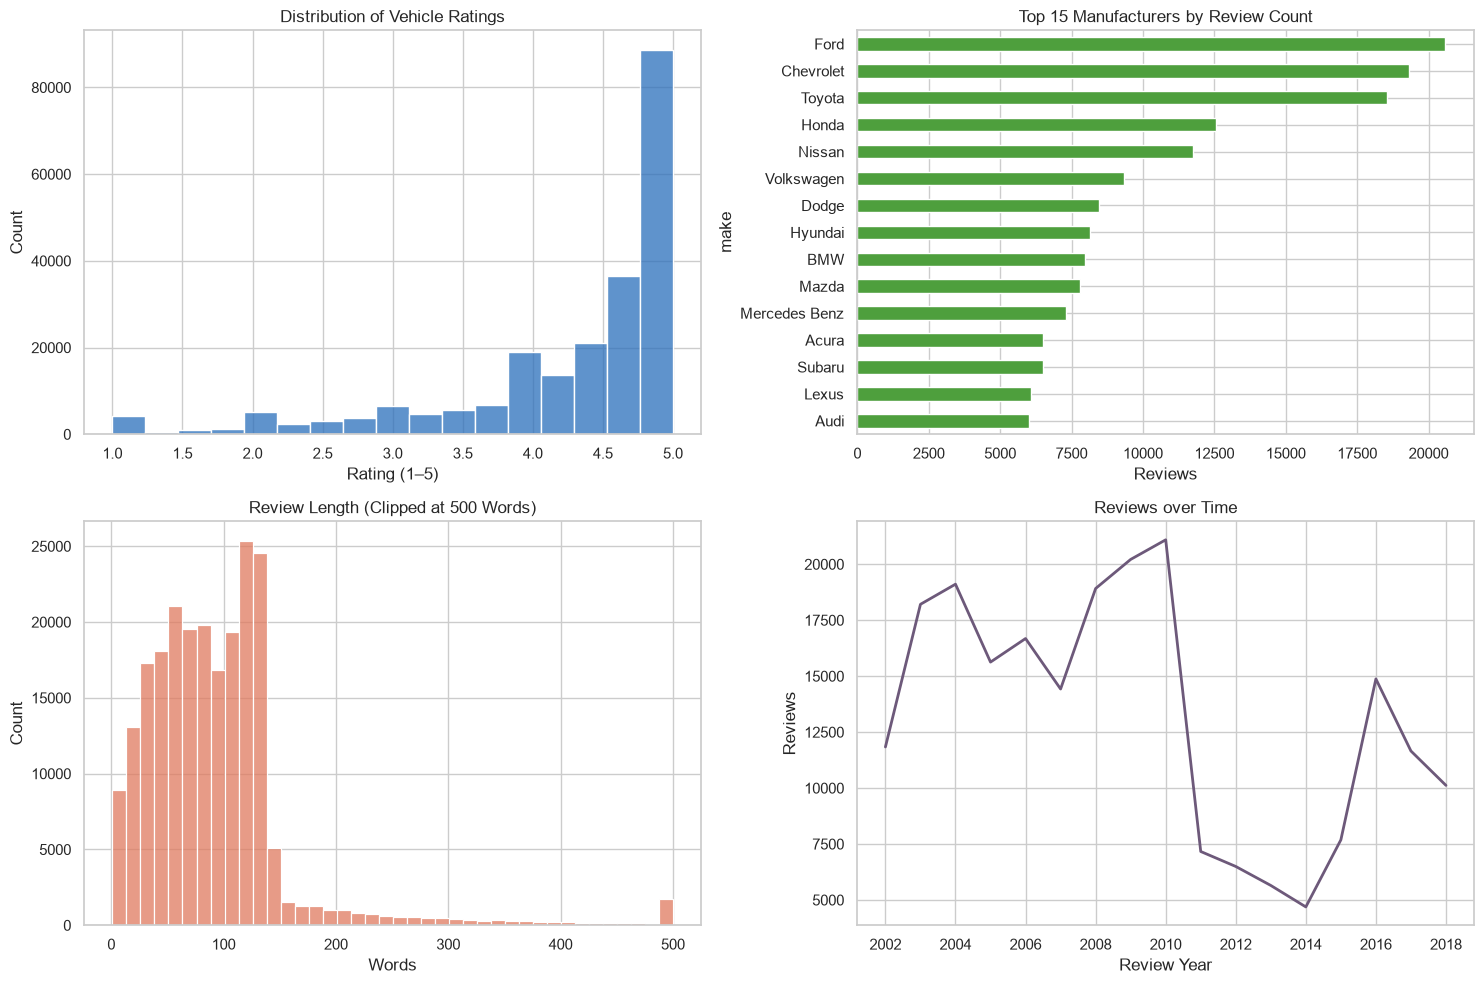

In [7]:
# Visualize rating behavior, manufacturer coverage, review length, and review years.
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.histplot(reviews["rating"], bins=17, ax=axes[0, 0], color="#2A6FBB")
axes[0, 0].set(title="Distribution of Vehicle Ratings", xlabel="Rating (1–5)")

top_makes = reviews["make"].value_counts().head(15).sort_values()
top_makes.plot(kind="barh", ax=axes[0, 1], color="#4E9F3D")
axes[0, 1].set(title="Top 15 Manufacturers by Review Count", xlabel="Reviews")

sns.histplot(
    reviews["review_word_count"].clip(upper=500), bins=40,
    ax=axes[1, 0], color="#E07A5F"
)
axes[1, 0].set(title="Review Length (Clipped at 500 Words)", xlabel="Words")

reviews_per_year = reviews.dropna(subset=["review_date"]).groupby(
    reviews["review_date"].dt.year
).size()
reviews_per_year.plot(ax=axes[1, 1], color="#6D597A", linewidth=2)
axes[1, 1].set(title="Reviews over Time", xlabel="Review Year", ylabel="Reviews")

plt.tight_layout()
plt.show()

In [8]:
# Examine interaction sparsity and identify well-supported, highly rated vehicles.
reviews_per_user = reviews.groupby("user_id").size()
vehicle_summary = (
    reviews.groupby(["vehicle_title", "make"], as_index=False)
    .agg(average_rating=("rating", "mean"), review_count=("rating", "size"))
)

interaction_summary = pd.Series({
    "total_reviews": len(reviews),
    "unique_users": reviews["user_id"].nunique(),
    "unique_vehicles": reviews["vehicle_title"].nunique(),
    "users_with_2+_reviews": int((reviews_per_user >= 2).sum()),
    "median_reviews_per_user": reviews_per_user.median(),
    "maximum_reviews_by_one_user": reviews_per_user.max(),
}, name="value").to_frame()
display(interaction_summary)

print("Highest-rated vehicles with at least 25 reviews:")
display(
    vehicle_summary[vehicle_summary["review_count"] >= 25]
    .sort_values(["average_rating", "review_count"], ascending=False)
    .head(10)
    .round({"average_rating": 3})
)

,value
total_reviews,224444.0
unique_users,155074.0
unique_vehicles,29039.0
users_with_2+_reviews,15797.0
median_reviews_per_user,1.0
maximum_reviews_by_one_user,1132.0


Highest-rated vehicles with at least 25 reviews:


,vehicle_title,make,average_rating,review_count
13044,2007 Mercury Milan Sedan Premier 4dr Sedan (3.0L 6cyl 6A),Mercury,4.929,28
10408,2006 BMW Z4 Convertible 3.0si 2dr Convertible (3.0L 6cyl 6M),BMW,4.911,28
8065,2004 Lexus GS 300 Sedan 4dr Sedan (3.0L 6cyl 5A),Lexus,4.910,32
17727,2010 Mercury Milan Hybrid Sedan 4dr Sedan (2.5L 4cyl gas/electric hybrid CVT),Mercury,4.899,26
1280,1998 Lexus LS 400 Sedan 4dr Sedan,Lexus,4.895,43
3414,2001 Chevrolet Corvette Z06 Z06 2dr Coupe (5.7L 8cyl 6M),Chevrolet,4.879,32
6591,2003 Mercedes-Benz SLK-Class Convertible SLK230 Kompressor 2dr Roadster (2.3...,Mercedes Benz,4.870,26
3947,2001 Lexus LS 430 Sedan 4dr Sedan (4.3L 8cyl 5A),Lexus,4.868,54
3945,2001 Lexus GS 430 Sedan 4dr Sedan (4.3L 8cyl 5A),Lexus,4.866,28
3214,2000 Toyota Camry Solara Coupe SLE V6 2dr Coupe,Toyota,4.865,26


## 7. Content-Based Recommender

Reviews are aggregated at the exact vehicle-title level. TF–IDF converts the combined
review language into weighted unigram and bigram features. Cosine nearest neighbors then
retrieve vehicles with the most similar discussion patterns. Requiring at least three
reviews reduces noise from one-off items while retaining broad catalog coverage.

In [9]:
def build_review_corpus(text_series, max_reviews=12, characters_per_review=700):
    '''Join a bounded sample of reviews so popular cars do not dominate memory.'''
    return " ".join(
        text[:characters_per_review] for text in text_series.astype(str).head(max_reviews)
    )


content_start = time.perf_counter()
item_content = (
    reviews.groupby("vehicle_title", as_index=False)
    .agg(
        make=("make", "first"),
        model_year=("model_year", "first"),
        average_rating=("rating", "mean"),
        review_count=("rating", "size"),
        review_corpus=("content_text", build_review_corpus),
    )
)
item_content = item_content[item_content["review_count"] >= 3].reset_index(drop=True)

# Limit the vocabulary for practical Colab memory use while retaining useful phrases.
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=12_000,
    sublinear_tf=True,
    dtype=np.float32,
)
tfidf_matrix = tfidf_vectorizer.fit_transform(item_content["review_corpus"])

normalize_title = lambda value: re.sub(r"\s+", " ", str(value).strip().lower())
title_to_content_index = {
    normalize_title(title): index
    for index, title in enumerate(item_content["vehicle_title"])
}
content_fit_seconds = time.perf_counter() - content_start

def top_content_neighbors(query_index, n):
    '''Return top TF–IDF cosine neighbors using fast sparse multiplication.'''
    # TfidfVectorizer L2-normalizes rows, so their dot product equals cosine similarity.
    similarities = (tfidf_matrix @ tfidf_matrix[query_index].T).toarray().ravel()
    similarities[query_index] = -np.inf
    n = min(int(n), len(similarities) - 1)
    candidate_indices = np.argpartition(-similarities, n - 1)[:n]
    ordered_indices = candidate_indices[np.argsort(-similarities[candidate_indices])]
    return ordered_indices, similarities[ordered_indices]

print(f"Content catalog: {len(item_content):,} vehicles")
print(f"TF–IDF matrix shape: {tfidf_matrix.shape}")
print(f"TF–IDF nonzero values: {tfidf_matrix.nnz:,}")
print(f"Content model fit time: {content_fit_seconds:.2f} seconds")

Content catalog: 18,287 vehicles
TF–IDF matrix shape: (18287, 12000)
TF–IDF nonzero values: 5,236,968
Content model fit time: 61.25 seconds


In [10]:
def content_based_details(title, n=10):
    '''Return a detailed table of vehicles textually similar to the supplied title.'''
    key = normalize_title(title)
    if key not in title_to_content_index:
        raise ValueError(
            "Vehicle title not found in the content catalog. Use an exact title from item_content."
        )

    query_index = title_to_content_index[key]
    indices, similarities = top_content_neighbors(query_index, n)
    result = item_content.iloc[indices].copy()
    result["content_similarity"] = similarities
    return result[[
        "vehicle_title", "make", "model_year", "average_rating",
        "review_count", "content_similarity"
    ]].reset_index(drop=True)


def content_based_recommender(title, n=10):
    '''Return a list containing n vehicle titles similar to the input title.'''
    return content_based_details(title, n)["vehicle_title"].tolist()


# Demonstrate the required function using the most-reviewed eligible vehicle.
demo_content_title = item_content.loc[item_content["review_count"].idxmax(), "vehicle_title"]
print(f"Query vehicle: {demo_content_title}")
print("Recommended titles:")
print(content_based_recommender(demo_content_title, 5))
display(content_based_details(demo_content_title, 10).round(3))

Query vehicle: 2002 Acura RSX Type-S Type-S 2dr Hatchback (2.0L 4cyl 6M)
Recommended titles:
['1999 Acura Integra Hatchback GS-R 2dr Hatchback', '2004 Acura RSX Type-S Type-S 2dr Hatchback (2.0L 4cyl 6M)', '1998 Acura Integra Hatchback GS-R 2dr Hatchback', '2002 Acura RSX Hatchback 2dr Hatchback (2.0L 4cyl 5M)', '2006 Acura RSX Hatchback 2dr Hatchback (2.0L 4cyl 5M)']


,vehicle_title,make,model_year,average_rating,review_count,content_similarity
0,1999 Acura Integra Hatchback GS-R 2dr Hatchback,Acura,1999,4.759,14,0.209
1,2004 Acura RSX Type-S Type-S 2dr Hatchback (2.0L 4cyl 6M),Acura,2004,4.587,95,0.207
2,1998 Acura Integra Hatchback GS-R 2dr Hatchback,Acura,1998,4.846,13,0.202
3,2002 Acura RSX Hatchback 2dr Hatchback (2.0L 4cyl 5M),Acura,2002,4.777,78,0.198
4,2006 Acura RSX Hatchback 2dr Hatchback (2.0L 4cyl 5M),Acura,2006,4.538,13,0.196
5,2006 Acura TL Sedan 4dr Sedan w/Nav System (3.2L 6cyl 5A),Acura,2006,4.667,39,0.194
6,2003 Acura RSX Hatchback 2dr Hatchback (2.0L 4cyl 5M),Acura,2003,4.686,33,0.189
7,2003 Acura RSX Type-S Type-S 2dr Hatchback (2.0L 4cyl 6M),Acura,2003,4.687,95,0.189
8,2005 Acura RSX Type-S Type-S 2dr Hatchback (2.0L 4cyl 6M),Acura,2005,4.776,72,0.184
9,2006 Acura RSX Type-S Type-S 2dr Hatchback (2.0L 4cyl 6M),Acura,2006,4.796,46,0.180


In [11]:
# Evaluate content coherence: how often do top neighbors share the query manufacturer?
evaluation_queries = (
    item_content.sort_values("review_count", ascending=False).head(100).index.to_numpy()
)

same_make_scores = []
close_year_scores = []
for query_index in evaluation_queries:
    neighbor_indices, _ = top_content_neighbors(query_index, 10)
    query_make = item_content.loc[query_index, "make"]
    query_year = item_content.loc[query_index, "model_year"]
    neighbor_rows = item_content.iloc[neighbor_indices]
    same_make_scores.append((neighbor_rows["make"] == query_make).mean())
    if pd.notna(query_year):
        close_year_scores.append(
            (neighbor_rows["model_year"].sub(query_year).abs() <= 3).mean()
        )

content_metrics = pd.DataFrame({
    "metric": ["Same-make precision@10", "Within-3-years precision@10"],
    "value": [np.mean(same_make_scores), np.mean(close_year_scores)],
})
display(content_metrics.round(3))

,metric,value
0,Same-make precision@10,0.703
1,Within-3-years precision@10,0.652


## 8. Collaborative Recommender Using SVD

Collaborative filtering requires repeat interactions. Duplicate user–vehicle ratings are
averaged, and iterative k-core filtering retains users with at least three vehicles and
vehicles with at least five users. One rating per user is held out for testing. Ratings are
centered by each user’s training mean before applying sparse truncated SVD.

In [12]:
# Average any duplicate ratings so each user–vehicle pair is represented once.
interactions = (
    reviews.groupby(["user_id", "vehicle_title"], as_index=False)
    .agg(rating=("rating", "mean"))
)

# Keep items supported by the content model so hybrid scores are always available.
interactions = interactions[
    interactions["vehicle_title"].isin(set(item_content["vehicle_title"]))
].copy()


def iterative_k_core(frame, min_user_items=3, min_item_users=5):
    '''Repeatedly remove sparse users/items until both support rules hold.'''
    core = frame.copy()
    while True:
        previous_size = len(core)
        user_counts = core.groupby("user_id")["vehicle_title"].transform("size")
        core = core[user_counts >= min_user_items]
        item_counts = core.groupby("vehicle_title")["user_id"].transform("size")
        core = core[item_counts >= min_item_users]
        if len(core) == previous_size:
            return core.reset_index(drop=True)


core_interactions = iterative_k_core(interactions)

print(f"All unique user–vehicle interactions: {len(interactions):,}")
print(f"K-core interactions: {len(core_interactions):,}")
print(f"K-core users: {core_interactions['user_id'].nunique():,}")
print(f"K-core vehicles: {core_interactions['vehicle_title'].nunique():,}")

All unique user–vehicle interactions: 206,717
K-core interactions: 26,662
K-core users: 2,378
K-core vehicles: 3,384


In [13]:
# Randomly hold out one interaction per user for honest out-of-sample evaluation.
shuffled = core_interactions.sample(frac=1, random_state=RANDOM_STATE)
test_indices = shuffled.groupby("user_id", sort=False).head(1).index
test_interactions = core_interactions.loc[test_indices].copy()
train_interactions = core_interactions.drop(index=test_indices).copy()

# Remove rare test items that disappeared from the training fold.
trained_titles = set(train_interactions["vehicle_title"])
test_interactions = test_interactions[
    test_interactions["vehicle_title"].isin(trained_titles)
].copy()

user_ids = sorted(train_interactions["user_id"].unique())
item_titles = sorted(train_interactions["vehicle_title"].unique())
user_to_index = {user_id: index for index, user_id in enumerate(user_ids)}
item_to_index = {title: index for index, title in enumerate(item_titles)}

# Center each rating by that user's training mean to reduce rating-scale bias.
user_means = train_interactions.groupby("user_id")["rating"].mean()
train_interactions["centered_rating"] = (
    train_interactions["rating"] - train_interactions["user_id"].map(user_means)
)
train_rows = train_interactions["user_id"].map(user_to_index).to_numpy()
train_columns = train_interactions["vehicle_title"].map(item_to_index).to_numpy()

rating_matrix = csr_matrix(
    (train_interactions["centered_rating"], (train_rows, train_columns)),
    shape=(len(user_ids), len(item_titles)),
    dtype=np.float32,
)

# Learn latent preference factors without constructing a dense user–item matrix.
MAX_LATENT_FEATURES = 50
latent_features = min(MAX_LATENT_FEATURES, min(rating_matrix.shape) - 1)
svd_start = time.perf_counter()
svd_model = TruncatedSVD(
    n_components=latent_features,
    n_iter=10,
    random_state=RANDOM_STATE,
)
user_factors = svd_model.fit_transform(rating_matrix)
item_factors = svd_model.components_.T
svd_fit_seconds = time.perf_counter() - svd_start

matrix_density = rating_matrix.nnz / (rating_matrix.shape[0] * rating_matrix.shape[1])
print(f"Training matrix shape: {rating_matrix.shape}")
print(f"Matrix density: {matrix_density:.6%}")
print(f"Latent features: {latent_features}")
print(f"Explained variance: {svd_model.explained_variance_ratio_.sum():.3f}")
print(f"SVD fit time: {svd_fit_seconds:.2f} seconds")

Training matrix shape: (2378, 3384)
Matrix density: 0.301771%
Latent features: 50
Explained variance: 0.384
SVD fit time: 0.16 seconds


In [14]:
def predict_svd_rating(user_id, vehicle_title, k=None):
    '''Predict one rating, optionally using only the first k latent features.'''
    if user_id not in user_to_index or vehicle_title not in item_to_index:
        return np.nan
    used_features = latent_features if k is None else max(1, min(int(k), latent_features))
    user_index = user_to_index[user_id]
    item_index = item_to_index[vehicle_title]
    residual = np.dot(
        user_factors[user_index, :used_features],
        item_factors[item_index, :used_features],
    )
    return float(np.clip(user_means[user_id] + residual, 1, 5))


# Compare SVD against global-mean and user-mean baselines on held-out ratings.
test_predictions = np.array([
    predict_svd_rating(row.user_id, row.vehicle_title)
    for row in test_interactions.itertuples()
])
global_mean = train_interactions["rating"].mean()
global_predictions = np.full(len(test_interactions), global_mean)
user_mean_predictions = test_interactions["user_id"].map(user_means).to_numpy()
actual_ratings = test_interactions["rating"].to_numpy()

evaluation_results = pd.DataFrame([
    {
        "model": "Global mean baseline",
        "RMSE": np.sqrt(mean_squared_error(actual_ratings, global_predictions)),
        "MAE": mean_absolute_error(actual_ratings, global_predictions),
    },
    {
        "model": "User mean baseline",
        "RMSE": np.sqrt(mean_squared_error(actual_ratings, user_mean_predictions)),
        "MAE": mean_absolute_error(actual_ratings, user_mean_predictions),
    },
    {
        "model": f"Centered SVD ({latent_features} factors)",
        "RMSE": np.sqrt(mean_squared_error(actual_ratings, test_predictions)),
        "MAE": mean_absolute_error(actual_ratings, test_predictions),
    },
])
display(evaluation_results.round(4))

svd_rmse = evaluation_results.loc[
    evaluation_results["model"].str.startswith("Centered SVD"), "RMSE"
].iloc[0]
global_rmse = evaluation_results.loc[
    evaluation_results["model"] == "Global mean baseline", "RMSE"
].iloc[0]
if svd_rmse < global_rmse:
    print("SVD improves RMSE over the global-mean baseline on held-out ratings.")
else:
    print(
        "SVD does not beat the strong global-mean baseline on this very sparse dataset. "
        "It is retained because it supplies personalized ranking, while the result is "
        "reported honestly as a limitation."
    )

,model,RMSE,MAE
0,Global mean baseline,0.8933,0.6765
1,User mean baseline,0.9650,0.6936
2,Centered SVD (50 factors),0.9647,0.6933


SVD does not beat the strong global-mean baseline on this very sparse dataset. It is retained because it supplies personalized ranking, while the result is reported honestly as a limitation.


In [15]:
# Cache metadata and rated-item sets to make repeated recommendations fast.
item_metadata = item_content.set_index("vehicle_title")
seen_titles_by_user = (
    core_interactions.groupby("user_id")["vehicle_title"].agg(set).to_dict()
)


def collaborative_recommender(user_id, n=10):
    '''Return n unseen vehicle titles with the highest personalized SVD predictions.'''
    if user_id not in user_to_index:
        raise ValueError("Unknown or too-sparse user_id. Choose an ID from core_interactions.")

    user_index = user_to_index[user_id]
    scores = user_means[user_id] + user_factors[user_index] @ item_factors.T
    scores = np.clip(scores, 1, 5)
    seen_titles = seen_titles_by_user.get(user_id, set())

    ranked_indices = np.argsort(scores)[::-1]
    recommendations = []
    for item_index in ranked_indices:
        title = item_titles[item_index]
        if title not in seen_titles:
            recommendations.append(title)
        if len(recommendations) == n:
            break
    return recommendations


def collaborative_details(user_id, n=10):
    '''Return collaborative recommendations with predicted rating and metadata.'''
    titles = collaborative_recommender(user_id, n)
    result = item_metadata.loc[titles, [
        "make", "model_year", "average_rating", "review_count"
    ]].reset_index()
    result["predicted_rating"] = [
        predict_svd_rating(user_id, title) for title in titles
    ]
    return result.sort_values("predicted_rating", ascending=False).reset_index(drop=True)


# Select a moderately active reviewer; this is more realistic than an extreme account.
core_user_counts = core_interactions["user_id"].value_counts()
realistic_demo_users = core_user_counts[
    core_user_counts.between(15, 30)
]
demo_user_id = realistic_demo_users.index[0]
print(f"Demonstration user: {demo_user_id}")
print(f"Known ratings: {len(seen_titles_by_user[demo_user_id])}")
print("Recommended titles:")
print(collaborative_recommender(demo_user_id, 5))
display(collaborative_details(demo_user_id, 10).round(3))

Demonstration user: U043212
Known ratings: 30
Recommended titles:
['2005 Nissan Maxima Sedan 3.5 SL 4dr Sedan (3.5L 6cyl 5A)', '2008 BMW X3 SUV 3.0si 4dr SUV AWD (3.0L 6cyl 6M)', '2014 Ford Focus Hatchback SE 4dr Hatchback (2.0L 4cyl 5M)', '2004 Chevrolet Aveo Hatchback 4dr Hatchback (1.6L 4cyl 5M)', '2012 Ford Fiesta Hatchback SE 4dr Hatchback (1.6L 4cyl 5M)']


,vehicle_title,make,model_year,average_rating,review_count,predicted_rating
0,2005 Nissan Maxima Sedan 3.5 SL 4dr Sedan (3.5L 6cyl 5A),Nissan,2005,3.661,28,4.553
1,2008 BMW X3 SUV 3.0si 4dr SUV AWD (3.0L 6cyl 6M),BMW,2008,3.764,45,4.545
2,2014 Ford Focus Hatchback SE 4dr Hatchback (2.0L 4cyl 5M),Ford,2014,1.995,53,4.544
3,2004 Chevrolet Aveo Hatchback 4dr Hatchback (1.6L 4cyl 5M),Chevrolet,2004,3.556,29,4.544
4,2012 Ford Fiesta Hatchback SE 4dr Hatchback (1.6L 4cyl 5M),Ford,2012,2.604,18,4.542
5,2006 Dodge Grand Caravan Minivan SXT 4dr Ext Minivan (3.8L 6cyl 4A),Dodge,2006,3.943,55,4.540
6,2002 Ford Explorer SUV XLT 2WD 4dr SUV (4.0L 6cyl 5A),Ford,2002,3.472,9,4.537
7,2005 Chevrolet Colorado Regular Cab 2dr Regular Cab Z85 Rwd SB (2.8L 4cyl 5M),Chevrolet,2005,3.792,12,4.536
8,2007 GMC Yukon XL SUV Denali 4dr SUV AWD (6.2L 8cyl 6A),GMC,2007,4.378,38,4.536
9,2009 Audi A4 Sedan 2.0T Premium 4dr Sedan (2.0L 4cyl Turbo CVT),Audi,2009,3.294,20,4.536


## 9. Hybrid Recommender

The hybrid model first retrieves a content-similar candidate pool. It then predicts this
user’s rating for each candidate using the first `k` SVD latent features. Both signals are
min–max normalized and combined. The default gives 55% weight to content relevance and 45%
to collaborative preference. Already-rated vehicles are excluded.

In [16]:
def minmax_scale(values):
    '''Scale a numeric array to 0–1, handling constant arrays safely.'''
    values = np.asarray(values, dtype=float)
    value_range = values.max() - values.min()
    if value_range == 0:
        return np.ones_like(values)
    return (values - values.min()) / value_range


def hybrid_recommender(
    title,
    user_id,
    k=20,
    n_recommendations=10,
    content_weight=0.55,
    candidate_pool=100,
):
    '''Return personalized, content-relevant vehicles in an informative DataFrame.

    Parameters
    ----------
    title : str
        Exact vehicle title used as the content anchor.
    user_id : str
        Anonymous user identifier from the collaborative k-core.
    k : int
        Number of trained SVD latent features used in personalized scoring.
    n_recommendations : int
        Number of final rows returned.
    content_weight : float
        Weight assigned to cosine similarity; collaboration receives 1 - this value.
    candidate_pool : int
        Number of content neighbors considered before personalization.
    '''
    if user_id not in user_to_index:
        raise ValueError("Unknown or too-sparse user_id. Choose an ID from core_interactions.")
    if not 0 <= content_weight <= 1:
        raise ValueError("content_weight must be between 0 and 1.")

    key = normalize_title(title)
    if key not in title_to_content_index:
        raise ValueError("Vehicle title not found in the content catalog.")

    query_index = title_to_content_index[key]
    indices, similarities = top_content_neighbors(query_index, candidate_pool)
    candidates = item_content.iloc[indices].copy()
    candidates["content_similarity"] = similarities

    # Restrict to collaborative items and remove vehicles already rated by this user.
    seen_titles = seen_titles_by_user.get(user_id, set())
    candidates = candidates[
        candidates["vehicle_title"].isin(item_to_index)
        & ~candidates["vehicle_title"].isin(seen_titles)
    ].copy()
    if candidates.empty:
        return pd.DataFrame()

    used_features = max(1, min(int(k), latent_features))
    user_index = user_to_index[user_id]
    candidate_indices = candidates["vehicle_title"].map(item_to_index).to_numpy()
    residual_scores = (
        item_factors[candidate_indices, :used_features]
        @ user_factors[user_index, :used_features]
    )
    candidates["predicted_rating"] = np.clip(
        user_means[user_id] + residual_scores, 1, 5
    )

    candidates["content_score_scaled"] = minmax_scale(candidates["content_similarity"])
    candidates["collaborative_score_scaled"] = minmax_scale(candidates["predicted_rating"])
    candidates["hybrid_score"] = (
        content_weight * candidates["content_score_scaled"]
        + (1 - content_weight) * candidates["collaborative_score_scaled"]
    )

    return (
        candidates.sort_values("hybrid_score", ascending=False)
        .head(n_recommendations)[[
            "vehicle_title", "make", "model_year", "average_rating",
            "review_count", "content_similarity", "predicted_rating", "hybrid_score"
        ]]
        .reset_index(drop=True)
    )


# Anchor the hybrid example on this user's highest-rated content-eligible vehicle.
demo_user_history = core_interactions[
    core_interactions["user_id"] == demo_user_id
].sort_values("rating", ascending=False)
demo_hybrid_title = demo_user_history.iloc[0]["vehicle_title"]

print(f"Hybrid user: {demo_user_id}")
print(f"Anchor vehicle: {demo_hybrid_title}")
display(hybrid_recommender(demo_hybrid_title, demo_user_id, k=20).round(3))

Hybrid user: U043212
Anchor vehicle: 1997 Cadillac Catera Sedan 4dr Sedan


,vehicle_title,make,model_year,average_rating,review_count,content_similarity,predicted_rating,hybrid_score
0,1999 Volkswagen Passat Sedan GLX V6 4dr Sedan,Volkswagen,1999,3.875,14,0.203,4.500,0.762
1,1998 Cadillac Catera Sedan 4dr Sedan,Cadillac,1998,3.569,63,0.195,4.506,0.743
2,1999 Chrysler Sebring Convertible JXi 2dr Convertible,Chrysler,1999,4.186,41,0.197,4.500,0.667
3,2000 Mercedes-Benz M-Class SUV ML320 4dr SUV AWD,Mercedes Benz,2000,3.634,44,0.199,4.497,0.660
4,2001 Cadillac Catera Sedan 4dr Sedan (3.0L 6cyl 4A),Cadillac,2001,3.756,40,0.199,4.497,0.648
5,2002 Volkswagen Jetta Sedan GLS 1.8T 4dr Sedan (1.8L 4cyl Turbo 5M),Volkswagen,2002,3.300,25,0.194,4.500,0.628
6,2002 Ford Focus Hatchback ZX5 4dr Hatchback (2.0L 4cyl 5M),Ford,2002,4.048,34,0.192,4.501,0.606
7,1999 Volkswagen Jetta Sedan GL 4dr Sedan (midyear),Volkswagen,1999,3.500,18,0.192,4.500,0.581
8,2003 Dodge Neon Sedan SE 4dr Sedan (2.0L 4cyl 5M),Dodge,2003,4.098,14,0.176,4.515,0.554
9,2000 GMC Jimmy SUV SLE 4dr SUV,GMC,2000,3.240,12,0.190,4.500,0.543


## 10. Practicality, Efficiency, and Model Comparison

In [17]:
# Measure recommendation latency and summarize practical model characteristics.
start = time.perf_counter()
_ = content_based_recommender(demo_content_title, 10)
content_latency_ms = (time.perf_counter() - start) * 1000

start = time.perf_counter()
_ = collaborative_recommender(demo_user_id, 10)
collaborative_latency_ms = (time.perf_counter() - start) * 1000

start = time.perf_counter()
sample_hybrid_recommendations = hybrid_recommender(
    demo_hybrid_title, demo_user_id, k=20
)
hybrid_latency_ms = (time.perf_counter() - start) * 1000

efficiency_table = pd.DataFrame({
    "model": ["Content-based", "Collaborative SVD", "Hybrid"],
    "fit_seconds": [content_fit_seconds, svd_fit_seconds, np.nan],
    "sample_query_ms": [content_latency_ms, collaborative_latency_ms, hybrid_latency_ms],
    "primary_strength": [
        "Explainable similarity and cold-start items",
        "Personalization from rating behavior",
        "Balances relevance and personalization",
    ],
    "primary_limitation": [
        "No user preference signal",
        "Needs repeat users and supported items",
        "Requires both models and weight selection",
    ],
})
display(efficiency_table.round(3))

,model,fit_seconds,sample_query_ms,primary_strength,primary_limitation
0,Content-based,61.247,91.023,Explainable similarity and cold-start items,No user preference signal
1,Collaborative SVD,0.158,0.563,Personalization from rating behavior,Needs repeat users and supported items
2,Hybrid,NaN,96.011,Balances relevance and personalization,Requires both models and weight selection


In [18]:
# Estimate collaborative recommendation coverage across a reproducible user sample.
sampled_users = rng.choice(user_ids, size=min(50, len(user_ids)), replace=False)
recommended_titles = set()
for sampled_user in sampled_users:
    recommended_titles.update(collaborative_recommender(sampled_user, 10))

coverage = len(recommended_titles) / len(item_titles)
practicality_metrics = pd.DataFrame({
    "metric": [
        "Collaborative catalog coverage (50 users, top 10)",
        "Content catalog vehicles",
        "Collaborative catalog vehicles",
        "Held-out collaborative ratings",
    ],
    "value": [coverage, len(item_content), len(item_titles), len(test_interactions)],
})
display(practicality_metrics)

,metric,value
0,"Collaborative catalog coverage (50 users, top 10)",0.099586
1,Content catalog vehicles,18287.000000
2,Collaborative catalog vehicles,3384.000000
3,Held-out collaborative ratings,2378.000000


## 11. Save Reproducible Results

Small result tables are saved for inspection. The raw source files remain unchanged.
In Colab, outputs are written to `/content/project_outputs`; locally they are written to
the project’s `outputs` folder.

In [19]:
# Choose a writable output directory for either local execution or Colab.
local_output_directory = Path("../outputs")
OUTPUT_DIR = (
    local_output_directory
    if local_output_directory.parent.exists()
    else Path("/content/project_outputs")
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

item_content.drop(columns="review_corpus").to_csv(
    OUTPUT_DIR / "clean_vehicle_catalog.csv", index=False
)
evaluation_results.to_csv(OUTPUT_DIR / "collaborative_metrics.csv", index=False)
sample_hybrid_recommendations.to_csv(
    OUTPUT_DIR / "sample_hybrid_recommendations.csv", index=False
)

print(f"Saved outputs to: {OUTPUT_DIR.resolve()}")
for output_file in sorted(OUTPUT_DIR.glob("*.csv")):
    print(f"- {output_file.name} ({output_file.stat().st_size / 1024:.1f} KB)")

Saved outputs to: C:\UTampa\DSC201\Project_1\outputs
- clean_vehicle_catalog.csv (1588.7 KB)
- collaborative_metrics.csv (0.2 KB)
- sample_hybrid_recommendations.csv (1.4 KB)


## 12. Conclusions

This project produced three complementary vehicle recommenders from real consumer review
data. The content model uses review language to explain similarity and can serve items
without repeat-user history. The centered sparse SVD model provides personalization while
avoiding an impractical dense ratings matrix. The hybrid model limits candidates by content
relevance and then re-ranks them using a chosen number of collaborative latent features.

The offline RMSE/MAE table should be interpreted alongside practical constraints. Review
data are highly sparse, author names are not guaranteed to represent permanent accounts,
and historical ratings can contain popularity and selection bias. The k-core improves model
reliability but reduces coverage for new users and rare vehicles. In production, this system
should add explicit onboarding preferences, monitor recommendation diversity, and retrain as
new ratings arrive.

### Required function interfaces completed

- `content_based_recommender(title, n)` → list of similar vehicle titles
- `collaborative_recommender(user_id, n)` → list of personalized vehicle titles
- `hybrid_recommender(title, user_id, k, ...)` → DataFrame of combined recommendations